In [ ]:

!pip install "gymnasium[toy-text]" numpy matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 47.8 MB/s eta 0:00:00


In [ ]:
from google.colab import files

files.download("frozen_lake_qtable.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

pd.DataFrame(
    q_table,
    columns=["Left", "Down", "Right", "Up"]
)

,Left,Down,Right,Up
0,0.735092,0.773781,0.773781,0.735092
1,0.735092,0.000000,0.814506,0.773781
2,0.773781,0.857375,0.773781,0.814506
3,0.814506,0.000000,0.773781,0.773781
4,0.773781,0.814506,0.000000,0.735092
5,0.000000,0.000000,0.000000,0.000000
6,0.000000,0.902500,0.000000,0.814506
7,0.000000,0.000000,0.000000,0.000000
8,0.814506,0.000000,0.857375,0.773781
9,0.814506,0.902500,0.902500,0.000000


In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("FrozenLake-v1", is_slippery=False)

print("Environment created successfully!")
print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)

env.close()

Environment created successfully!
Number of states: 16
Number of actions: 4


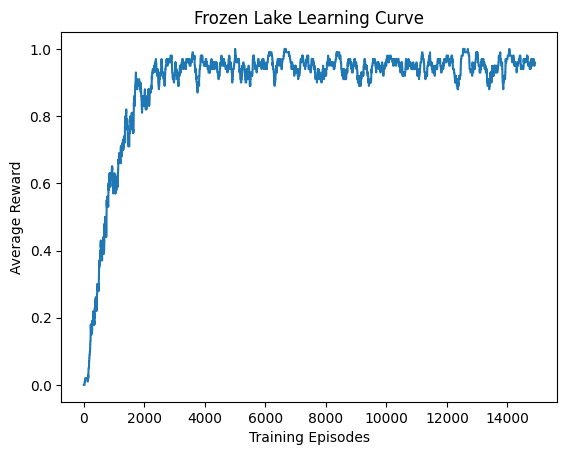

Training completed!
Q-table shape: (16, 4)
Success rate: 96.3 %


In [ ]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pickle

# Create Frozen Lake
env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=False
)

# Create Q-table
q = np.zeros((16, 4))

# Learning settings
episodes = 15000
learning_rate = 0.8
discount = 0.95
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.999

rewards = []

# Train the agent
for episode in range(episodes):
    state, info = env.reset()
    done = False
    total_reward = 0

    while not done:
        # Choose an action
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = int(np.argmax(q[state]))

        # Take the action
        next_state, reward, terminated, truncated, info = (
            env.step(action)
        )
        done = terminated or truncated

        # Update Q-value
        future_value = 0 if done else np.max(q[next_state])

        q[state, action] += learning_rate * (
            reward + discount * future_value
            - q[state, action]
        )

        state = next_state
        total_reward += reward

    rewards.append(total_reward)
    epsilon = max(epsilon * epsilon_decay, epsilon_min)

env.close()

# Plot learning progress
moving_avg = np.convolve(
    rewards, np.ones(100) / 100, mode="valid"
)

plt.plot(moving_avg)
plt.title("Frozen Lake Learning Curve")
plt.xlabel("Training Episodes")
plt.ylabel("Average Reward")
plt.show()

# Save the Q-table
with open("frozen_lake_qtable.pkl", "wb") as f:
    pickle.dump(q, f)

print("Training completed!")
print("Q-table shape:", q.shape)
print("Success rate:", np.mean(rewards[-1000:]) * 100, "%")


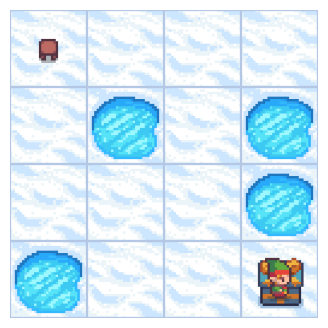

Final reward: 1
SUCCESS! The agent reached the goal!


In [ ]:

import gymnasium as gym
import numpy as np
import pickle
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time

# Load the trained Q-table
with open("frozen_lake_qtable.pkl", "rb") as f:
    q_table = pickle.load(f)

# Create the visual environment
env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=False,
    render_mode="rgb_array"
)

state, info = env.reset()
done = False
total_reward = 0

while not done:
    # Select the best action learned during training
    action = int(np.argmax(q_table[state]))

    next_state, reward, terminated, truncated, info = (
        env.step(action)
    )

    done = terminated or truncated
    state = next_state
    total_reward += reward

    # Display the environment
    frame = env.render()
    clear_output(wait=True)
    plt.figure(figsize=(4, 4))
    plt.imshow(frame)
    plt.axis("off")
    display(plt.gcf())
    plt.close()

    time.sleep(0.5)

env.close()

print("Final reward:", total_reward)

if total_reward == 1:
    print("SUCCESS! The agent reached the goal!")
else:
    print("The agent did not reach the goal. Retrain and try again.")
